<div style="background:linear-gradient(135deg,#2b0f27 0%,#5c2250 45%,#a64d8f 100%);color:white;padding:34px 30px;border-radius:12px;font-family:'Trebuchet MS','Segoe UI',sans-serif;"><div style="font-size:15px;letter-spacing:3px;color:#f0c6e3">PROYECTO · TALLER II · CIENCIA DE DATOS · INFERENCIA</div><div style="font-size:32px;font-weight:bold;margin:10px 0">🛍️ Pronóstico de unidades vendidas · Lencería Lizzy</div><div style="font-size:18px;color:#fbe3f3">Carga el modelo exportado y predice sobre fechas nuevas</div><hr style="border:0;border-top:1px solid #d08abd;margin:18px 0"><div style="font-size:17px"><b>Autora:</b> Lizzy Leyla Baron Barrero</div></div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Propósito de este notebook</b><br>Este archivo <b>no entrena nada</b>. Carga <code>modelo_ventas.joblib</code> (que genera el notebook <code>Proyecto_Final_Ventas_Lizzy.ipynb</code>) y lo usa para predecir las <b>unidades por día, lugar y tipo de prenda</b>. Como el archivo contiene el <b>pipeline completo</b> (codificación, escalado y modelo), basta indicar fecha, lugar y tipo: el pipeline prepara el resto igual que en el entrenamiento.<br><br><b>Requisito:</b> el archivo <code>modelo_ventas.joblib</code> debe estar en la misma carpeta. Ejecutar con <i>Kernel → Restart &amp; Run All</i>.</div>

<div style="border-left:6px solid #b8651b;background:#b8651b14;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#b8651b">⚠️ Recordatorio</b><br>El modelo se entrenó con ventas <b>estimadas</b> (reconstruidas), no registradas en uso real. Las predicciones muestran el flujo funcionando, <b>no son una previsión confiable del negocio</b>.</div>

<div style="background:linear-gradient(90deg,#4a1942,#8e3b7c 70%,#c06c9f);color:white;padding:14px 20px;border-radius:8px;margin-top:22px;font-family:'Trebuchet MS','Segoe UI',sans-serif;font-size:22px;font-weight:bold">🌸 1. Carga del modelo exportado</div>

In [1]:
import warnings, joblib, sklearn, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, HTML
warnings.filterwarnings("ignore")

FUENTE = "font-family:'Trebuchet MS','Segoe UI',sans-serif;"
def nota(titulo, cuerpo, color="#0e7c86", icono="🔎"):
    display(HTML(f'<div style="border-left:6px solid {color};background:{color}14;padding:12px 16px;margin:8px 0;'
                 f'border-radius:6px;{FUENTE}line-height:1.55"><b style="color:{color}">{icono} {titulo}</b><br>{cuerpo}</div>'))
def mostrar(d, alto=320):
    estilo = ("<style>.tabla{border-collapse:collapse;font-size:12px}.tabla th{position:sticky;top:0;background:#5c2250;"
              "color:white;padding:4px 8px}.tabla td{padding:3px 8px;border-bottom:1px solid #eadbe6;white-space:nowrap}</style>")
    display(HTML(estilo + f'<div style="max-height:{alto}px;overflow:auto;border:2px solid #5c2250;border-radius:6px">'
                 + d.to_html(max_rows=None, classes="tabla", border=0, na_rep="", float_format=lambda v: f"{v:.5g}") + "</div>"))

RUTA = Path("modelo_ventas.joblib")
if not RUTA.exists():
    raise FileNotFoundError("No se encuentra 'modelo_ventas.joblib'. Debe estar en la misma carpeta que este notebook.")
M = joblib.load(RUTA)
PIPE, FEATS, DIAS = M["pipeline"], M["features"], M["dias"]
TIPOS, LUGARES = M["tipos"], M["lugares"]
FECHA_CALOR = pd.Timestamp(M["fecha_calor"])
INICIO_TIPO = {t: pd.Timestamp(f) for t, f in M["inicio_tipo"].items()}
F_INI, F_FIN = pd.Timestamp(M["rango_entrenamiento"][0]), pd.Timestamp(M["rango_entrenamiento"][1])

if M["sklearn_version"].split(".")[:2] != sklearn.__version__.split(".")[:2]:
    print(f"⚠️ El modelo se guardó con scikit-learn {M['sklearn_version']} y aquí hay {sklearn.__version__}. "
          f"Si hay errores: pip install scikit-learn=={M['sklearn_version']}")
print(f"✔ Modelo cargado: {M['nombre_modelo']}  |  hiperparámetros: {M['hiperparametros']}")
print(f"  Entrenado con fechas {F_INI.date()} a {F_FIN.date()}  |  scikit-learn {M['sklearn_version']}")
print(f"  Tipos: {', '.join(TIPOS)}")
print(f"  Lugares: {', '.join(LUGARES)}")
nota("Métricas guardadas al entrenar (conjunto de prueba)", " · ".join(f"<b>{k}</b> = {v:.3f}" for k, v in M["metricas_test"].items())
     + "<br>Modelo de referencia (promedio): " + " · ".join(f"{k} = {v:.3f}" for k, v in M["metricas_referencia_test"].items()), "#0b6e4f", "✅")
nota("Origen de los datos", M["origen_datos"], "#b8651b", "⚠️")

✔ Modelo cargado: Gradient Boosting  |  hiperparámetros: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 200}
  Entrenado con fechas 2026-08-03 a 2026-11-17  |  scikit-learn 1.9.1
  Tipos: cacheteros, hombre, medias, nino, ropa_de_bano, ropa_interior_mujer, ropa_usada
  Lugares: feria_barrio_nuevo, mercado_lourdes


<div style="border-left:6px solid #0e7c86;background:#0e7c8614;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#0e7c86">🔎 Cómo leer esto</b><br>Confirma qué modelo se cargó, con qué configuración y con qué métricas en días que no vio. Si aparece un aviso de versión de scikit-learn, conviene instalar la misma versión con la que se guardó.</div>

<div style="background:linear-gradient(90deg,#4a1942,#8e3b7c 70%,#c06c9f);color:white;padding:14px 20px;border-radius:8px;margin-top:22px;font-family:'Trebuchet MS','Segoe UI',sans-serif;font-size:22px;font-weight:bold">🌸 2. Funciones de predicción</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Qué se hace y por qué</b><br>Se pide solo <b>fecha</b>, <b>lugar</b> y <b>tipo</b>. La función <code>construir</code> calcula día de la semana, mes, semana ISO y temporada de calor con las <b>mismas reglas del entrenamiento</b>. No imputa, escala ni codifica: eso lo hace el pipeline. También agrega un <b>aviso</b> cuando la consulta es poco confiable (fecha fuera del rango de entrenamiento o tipo que aún no se vendía).</div>

In [2]:
def construir(df):
    d = df.copy()
    d["fecha"] = pd.to_datetime(d["fecha"])
    d["dia_semana"] = d["fecha"].dt.dayofweek.map(dict(enumerate(DIAS)))
    d["mes"] = d["fecha"].dt.month
    d["semana_iso"] = d["fecha"].dt.isocalendar().week.astype(int)
    d["calor"] = (d["fecha"] >= FECHA_CALOR).astype(int)
    return d

def predecir(df):
    """df con columnas: fecha, lugar_venta, tipo. Devuelve una tabla con las unidades predichas y un aviso de confiabilidad."""
    d = construir(df)
    malos_t = sorted(set(d["tipo"]) - set(TIPOS)); malos_l = sorted(set(d["lugar_venta"]) - set(LUGARES))
    if malos_t or malos_l:
        raise ValueError(f"Valores desconocidos. Tipos válidos: {TIPOS}. Lugares válidos: {LUGARES}. Recibido: {malos_t + malos_l}")
    p = np.clip(PIPE.predict(d[FEATS]), 0, None)
    avisos = []
    for f, t in zip(d["fecha"], d["tipo"]):
        a = []
        if f < F_INI or f > F_FIN: a.append("fecha fuera del rango de entrenamiento (extrapolación)")
        if f < INICIO_TIPO[t]: a.append(f"el tipo '{t}' empezó a venderse el {INICIO_TIPO[t].date()}")
        avisos.append("; ".join(a))
    return pd.DataFrame({"fecha": d["fecha"].dt.date, "dia": d["dia_semana"], "lugar_venta": d["lugar_venta"], "tipo": d["tipo"],
                         "unidades_predichas": p.round(2), "unidades_aprox": np.rint(p).astype(int), "aviso": avisos}, index=df.index)

def predecir_uno(fecha, lugar, tipo):
    return float(predecir(pd.DataFrame([{"fecha": fecha, "lugar_venta": lugar, "tipo": tipo}]))["unidades_predichas"].iloc[0])
print("Funciones listas.")

Funciones listas.


<div style="background:linear-gradient(90deg,#4a1942,#8e3b7c 70%,#c06c9f);color:white;padding:14px 20px;border-radius:8px;margin-top:22px;font-family:'Trebuchet MS','Segoe UI',sans-serif;font-size:22px;font-weight:bold">🌸 3. Demostración 1: una consulta puntual</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Qué se hace y por qué</b><br>Se consulta una fecha, un lugar y un tipo. Ejemplo: <b>¿cuántos trajes de baño y mayas se esperan el martes 24 de noviembre de 2026 en la Feria de Barrio Nuevo?</b></div>

In [3]:
f, lugar, tipo = "2026-11-24", "feria_barrio_nuevo", "ropa_de_bano"
r = predecir(pd.DataFrame([{"fecha": f, "lugar_venta": lugar, "tipo": tipo}]))
mostrar(r, 100)
nota("Resultado", f"Para el <b>{f}</b> en <b>{lugar}</b>, el modelo espera unas <b>{r['unidades_predichas'].iloc[0]:.1f}</b> unidades de <b>{tipo}</b> "
     f"(≈ {r['unidades_aprox'].iloc[0]} prendas).", "#0b6e4f", "🛍️")

,fecha,dia,lugar_venta,tipo,unidades_predichas,unidades_aprox,aviso
0,2026-11-24,martes,feria_barrio_nuevo,ropa_de_bano,8.52,9,fecha fuera del rango de entrenamiento (extrapolación)


<div style="border-left:6px solid #0e7c86;background:#0e7c8614;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#0e7c86">🔎 Cómo leer esto</b><br>Las <b>unidades_predichas</b> son un promedio esperado (por eso puede tener decimales); <b>unidades_aprox</b> es el número redondeado. Si la columna <b>aviso</b> trae texto, la predicción es menos confiable: la fecha está fuera de lo que el modelo vio.</div>

In [4]:
try:
    import ipywidgets as w
    ent_f = w.DatePicker(description="Fecha:", value=pd.Timestamp("2026-11-24").date())
    ent_l = w.Dropdown(options=LUGARES, value="feria_barrio_nuevo", description="Lugar:")
    ent_t = w.Dropdown(options=TIPOS, value="ropa_de_bano", description="Tipo:")
    bot = w.Button(description="🛍️ Predecir", button_style="primary"); sal = w.Output()
    def clic(_):
        with sal:
            sal.clear_output(wait=True)
            if ent_f.value is None: print("Elegir una fecha."); return
            mostrar(predecir(pd.DataFrame([{"fecha": ent_f.value, "lugar_venta": ent_l.value, "tipo": ent_t.value}])), 100)
    bot.on_click(clic)
    display(HTML(f"<h3 style='color:#5c2250;{FUENTE}'>🧾 Formulario de consulta</h3>"))
    display(w.VBox([ent_f, ent_l, ent_t, bot, sal]))
except ImportError:
    print("ipywidgets no está instalado: usar predecir_uno('2026-11-24', 'feria_barrio_nuevo', 'ropa_de_bano') en su lugar.")

<div style="background:linear-gradient(90deg,#4a1942,#8e3b7c 70%,#c06c9f);color:white;padding:14px 20px;border-radius:8px;margin-top:22px;font-family:'Trebuchet MS','Segoe UI',sans-serif;font-size:22px;font-weight:bold">🌸 4. Demostración 2: pronóstico de una jornada completa</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Qué se hace y por qué</b><br>Para una fecha y un lugar se predicen <b>todos los tipos de prenda a la vez</b>. Sirve para ver cómo se reparte la venta esperada del día y qué mercadería llevar.</div>

,fecha,dia,lugar_venta,tipo,unidades_predichas,unidades_aprox,aviso
0,2026-11-24,martes,feria_barrio_nuevo,ropa_de_bano,8.52,9,fecha fuera del rango de entrenamiento (extrapolación)
1,2026-11-24,martes,feria_barrio_nuevo,ropa_interior_mujer,3.89,4,fecha fuera del rango de entrenamiento (extrapolación)
2,2026-11-24,martes,feria_barrio_nuevo,ropa_usada,2.75,3,fecha fuera del rango de entrenamiento (extrapolación)
3,2026-11-24,martes,feria_barrio_nuevo,medias,2.38,2,fecha fuera del rango de entrenamiento (extrapolación)
4,2026-11-24,martes,feria_barrio_nuevo,cacheteros,2.24,2,fecha fuera del rango de entrenamiento (extrapolación)
5,2026-11-24,martes,feria_barrio_nuevo,hombre,1.43,1,fecha fuera del rango de entrenamiento (extrapolación)
6,2026-11-24,martes,feria_barrio_nuevo,nino,0.31,0,fecha fuera del rango de entrenamiento (extrapolación)


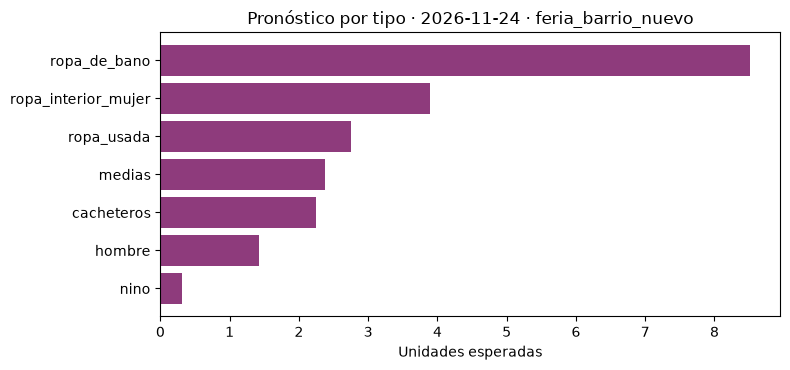

In [5]:
FECHA, LUGAR = "2026-11-24", "feria_barrio_nuevo"
q = pd.DataFrame({"fecha": FECHA, "lugar_venta": LUGAR, "tipo": TIPOS})
jornada = predecir(q).sort_values("unidades_predichas", ascending=False).reset_index(drop=True)
mostrar(jornada, 280)
plt.figure(figsize=(8, 3.8)); t = jornada.sort_values("unidades_predichas")
plt.barh(t["tipo"], t["unidades_predichas"], color="#8e3b7c"); plt.xlabel("Unidades esperadas")
plt.title(f"Pronóstico por tipo · {FECHA} · {LUGAR}"); plt.tight_layout(); plt.show()
nota("Resultado", f"Se esperan en total unas <b>{jornada['unidades_predichas'].sum():.0f}</b> prendas ese día. El tipo con más venta esperada es <b>{jornada.loc[0, 'tipo']}</b>.", "#0b6e4f", "🛍️")

<div style="border-left:6px solid #0e7c86;background:#0e7c8614;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#0e7c86">🔎 Cómo leer esto</b><br>Cada barra es la venta esperada de un tipo de prenda esa jornada. La suma da el volumen total esperado del día. Los tipos con valor cercano a 0 son los que el modelo espera que casi no se vendan.</div>

<div style="background:linear-gradient(90deg,#4a1942,#8e3b7c 70%,#c06c9f);color:white;padding:14px 20px;border-radius:8px;margin-top:22px;font-family:'Trebuchet MS','Segoe UI',sans-serif;font-size:22px;font-weight:bold">🌸 5. Demostración 3: varias fechas desde un archivo CSV</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Qué se hace y por qué</b><br>Se genera una <b>plantilla</b> (<code>plantilla_pronostico.csv</code>) con las columnas <code>fecha</code>, <code>lugar_venta</code> y <code>tipo</code>, se lee y se predice. Se puede editar la plantilla con otras fechas y volver a ejecutar la celda. El resultado se guarda en <code>resultado_pronostico.csv</code>. Además se suman las unidades por tipo: es la base para decidir <b>qué mercadería comprar</b>.</div>

In [6]:
fechas = ["2026-11-24", "2026-12-01", "2026-12-08"]          # tres martes consecutivos de la Feria de Barrio Nuevo
plantilla = pd.DataFrame([{"fecha": f, "lugar_venta": "feria_barrio_nuevo", "tipo": t} for f in fechas for t in TIPOS])
plantilla.to_csv("plantilla_pronostico.csv", index=False)
print("Plantilla creada: plantilla_pronostico.csv")

nuevos = pd.read_csv("plantilla_pronostico.csv")
res = predecir(nuevos)
res.to_csv("resultado_pronostico.csv", index=False)
print(f"{len(res)} consultas predichas · guardado en resultado_pronostico.csv")

compra = (res.pivot_table(index="tipo", columns="fecha", values="unidades_predichas", aggfunc="sum")
          .assign(total=lambda t: t.sum(axis=1)).sort_values("total", ascending=False))
mostrar(compra.round(1), 280)

Plantilla creada: plantilla_pronostico.csv
21 consultas predichas · guardado en resultado_pronostico.csv


fecha,2026-11-24,2026-12-01,2026-12-08,total
tipo,,,,
ropa_de_bano,8.5,8.5,8.5,25.6
ropa_interior_mujer,3.9,3.9,3.9,11.7
ropa_usada,2.8,2.8,2.8,8.2
medias,2.4,2.4,2.4,7.1
cacheteros,2.2,2.2,2.2,6.7
hombre,1.4,1.4,1.4,4.3
nino,0.3,0.3,0.3,0.9


<div style="border-left:6px solid #0e7c86;background:#0e7c8614;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#0e7c86">🔎 Cómo leer esto</b><br>Cada columna es una fecha y la última, <b>total</b>, suma las tres jornadas por tipo. Sirve como orientación de cuánto de cada tipo conviene tener para esas semanas. Diciembre queda <b>fuera del rango de entrenamiento</b> (que termina en noviembre), así que el modelo está extrapolando: la columna <i>aviso</i> de <code>resultado_pronostico.csv</code> lo indica.</div>

In [7]:
n_aviso = int((res["aviso"] != "").sum())
nota("Lectura automática", f"De {len(res)} consultas, <b>{n_aviso}</b> tienen aviso de baja confiabilidad (fecha fuera del rango de entrenamiento {F_INI.date()} a {F_FIN.date()} o tipo aún no vendido). "
     "Los modelos de árboles tienden a repetir los patrones del final del periodo de entrenamiento al extrapolar; por eso estas cifras no deben tomarse como previsión real.", "#b8651b", "⚠️")

<div style="background:linear-gradient(90deg,#4a1942,#8e3b7c 70%,#c06c9f);color:white;padding:14px 20px;border-radius:8px;margin-top:22px;font-family:'Trebuchet MS','Segoe UI',sans-serif;font-size:22px;font-weight:bold">🌸 6. Conclusión</div>

<div style="border-left:6px solid #0b6e4f;background:#0b6e4f14;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#0b6e4f">✅ Qué demuestra este notebook</b><br>Que el modelo exportado se puede <b>cargar en otro entorno sin reentrenar</b> y responder consultas nuevas (una, varias o desde un archivo), con avisos cuando la consulta cae fuera de lo que el modelo conoce. La utilidad real dependerá de reentrenarlo con ventas registradas por el sistema, pero el flujo completo (base de datos → dataset → modelo → inferencia) ya funciona de principio a fin.</div>